# GNN V1LD — Inférence sur instance fraîche (modèle multi-dataset)

Compare l'inférence directe du **modèle multi-dataset entraîné** (n=10/15/20, 100 epochs)  
à la borne sous-gradient de référence (precision=1, patience=30).  

L'instance est **générée à la volée** avec seed=9999 (hors dataset d'entraînement, seeds 0–399).  
Paramètres : n=10, m=5, N=50, ε=0.1 — même distribution Pisinger weakly-correlated que le training.

In [6]:
import os
os.environ.setdefault("OMP_NUM_THREADS", "1")  # login node

import sys, importlib
from pathlib import Path

import numpy as np
import torch
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

REPO = Path("../").resolve()
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))
sys.path.insert(0, str(REPO / "data" / "knapsack"))

import gnn.train_gnn_v1ld as T
importlib.reload(T)
from gnn.train_gnn_v1ld import (
    build_graph, GNN, lagrangian_v1ld, verify_v1ld,
    _solve_zeta_multi_bb,
)
from create_database_knapsack_pisinger import (
    generate_pisinger_instance, draw_mu, generate_scenario,
)

%matplotlib inline
plt.rcParams.update({"figure.dpi": 120, "font.size": 11})

[bnb_solver] C++ B&B chargé (solve_zeta_batch)


In [7]:
CKPT_PATH = (
    REPO / "gnn" / "runs"
    / "ckpt_multi_nodes_n10_m5_nodes_n15_m5_30k_nodes_n20_m5_20k"
      "_ep100_lr0.0003_bs32_h64_seed42_ep0099.pt"
)
assert CKPT_PATH.exists(), f"Checkpoint introuvable : {CKPT_PATH}"

ckpt = torch.load(CKPT_PATH, map_location="cpu")
print(f"Checkpoint : {CKPT_PATH.name}")
print(f"  epoch={ckpt['epoch']}  args={ckpt['args']}")

Checkpoint : ckpt_multi_nodes_n10_m5_nodes_n15_m5_30k_nodes_n20_m5_20k_ep100_lr0.0003_bs32_h64_seed42_ep0099.pt
  epoch=99  args={'inst_files': ['/local/scratch/romanlen.16478589.0/data/train_base_s30/instances_n10_m5.txt', '/local/scratch/romanlen.16478589.0/data/train_base_s30/instances_n15_m5.txt', '/local/scratch/romanlen.16478589.0/data/train_base_s30/instances_n20_m5.txt'], 'nodes_files': ['/local/scratch/romanlen.16478589.0/data/train_base_s30/nodes_n10_m5.txt', '/local/scratch/romanlen.16478589.0/data/train_base_s30/nodes_n15_m5_30k.txt', '/local/scratch/romanlen.16478589.0/data/train_base_s30/nodes_n20_m5_20k.txt'], 'n_list': [10, 15, 20], 'm': 5, 'data_dir': None, 'out_dir': '/project/6062881/romanl/Learning_bounds_CCCP/gnn/runs', 'train_frac': 0.8, 'seed': 42, 'n_epochs': 100, 'batch_size': 32, 'lr': 0.0003, 'eta_min': 1e-05, 'hidden': 64, 'eval_sample': 300, 'eval_every': 5, 'keep_ckpts': 10, 'num_workers': 4, 'weight_decay': 0.0, 'max_norm': 0.5, 'device': 'auto'}


## 1. Génération de l'instance fraîche

In [8]:
# Seed hors training (seeds 0–399 vus pendant l'entraînement)
SEED     = 9999
n, m, N  = 10, 5, 50
epsilon  = 0.10

rng_mu   = np.random.default_rng(SEED)
rng_scen = np.random.default_rng(SEED + 1_000_000)

det_inst = generate_pisinger_instance(
    n, m, alpha=0.5, R=1000, correlation="weakly_correlated", seed=SEED
)
mu = draw_mu(n, rng_mu)

# N scénarios stochastiques
A_scen = np.stack([generate_scenario(det_inst["A"], mu, rng_scen)
                   for _ in range(N)]).astype(np.float32)   # (N, m, n)
b_scen = np.tile(det_inst["b"], (N, 1)).astype(np.float32)  # (N, m)

inst = {
    "n": n, "m": m, "N": N,
    "epsilon": epsilon,
    "opt":     0.0,   # inconnu (pas de solveur Gecode ici)
    "c": det_inst["c"].astype(np.float32),
    "b": b_scen,
    "A": A_scen,
}

print(f"Instance  n={n}  m={m}  N={N}  ε={epsilon}  seed={SEED}")
print(f"  c : [{inst['c'].min():.0f}, {inst['c'].max():.0f}]")
print(f"  A : shape={inst['A'].shape}  ")
print(f"  Note : opt=0 (placeholder, pas de solveur Gecode)")

Instance  n=10  m=5  N=50  ε=0.1  seed=9999
  c : [253, 628]
  A : shape=(50, 5, 10)  
  Note : opt=0 (placeholder, pas de solveur Gecode)


## 2. Graphe racine et baselines

In [9]:
# Nœud racine : tous les items et scénarios libres (x_mask=2, z_mask=2)
node_rec = {
    "depth":     0,
    "curr_cost": 0.0,
    "x_mask":    np.full(n, 2, dtype=np.int8),
    "z_mask":    np.full(N, 2, dtype=np.int8),
    "b_res":     b_scen.copy(),
}

g = build_graph(inst, node_rec)
assert g is not None, "build_graph a retourné None"

print(f"Graphe racine : n_g={g.n_g}  N_z={g.N_z}  N={g.N}  m={g.m}")
print(f"  nœuds={g.x.shape[0]}  arêtes={g.edge_index.shape[1]}")

with torch.no_grad():
    lam0    = torch.zeros(g.N_z * g.n_g)
    l1_init = lagrangian_v1ld(lam0, g).item()

print(f"\nL1(λ=0) = {l1_init:.2f}  ← borne résiduelle de départ")

Graphe racine : n_g=10  N_z=50  N=50  m=5
  nœuds=500  arêtes=29000

L1(λ=0) = 3090.24  ← borne résiduelle de départ


## 3. Inférence GNN

In [10]:
model = GNN(m=5, hidden=64)
# Checkpoint v1 — architecture v2 ajoute norm_embed/norm_ctx (LayerNorm init=identité,
# effet négligeable pour l'inférence qualitative). Un checkpoint v2 est nécessaire pour
# une comparaison de performance rigoureuse.
missing, unexpected = model.load_state_dict(ckpt["model"], strict=False)
if missing:
    print(f"[WARN] Clés manquantes (archi v2 vs ckpt v1) : {missing}")
if unexpected:
    print(f"[WARN] Clés inattendues : {unexpected}")
model.eval()

with torch.no_grad():
    lam_gnn    = model(g)
    l1_gnn     = lagrangian_v1ld(lam_gnn, g).item()
    lam_np     = lam_gnn.numpy().reshape(g.N_z, g.n_g).astype(np.float64)

print(f"GNN seul :  L1 = {l1_gnn:.2f}")
print(f"  amélioration vs L1(0) : {(l1_init - l1_gnn) / l1_init * 100:.1f}%")
print(f"  |λ|_mean = {lam_gnn.abs().mean().item():.3f}")
print(f"  λ_min={lam_gnn.min().item():.3f}  λ_max={lam_gnn.max().item():.3f}")

[WARN] Clés manquantes (archi v2 vs ckpt v1) : ['norm_embed.weight', 'norm_embed.bias', 'norm_ctx.weight', 'norm_ctx.bias']
GNN seul :  L1 = 3037.84
  amélioration vs L1(0) : 1.7%
  |λ|_mean = 3.738
  λ_min=-7.303  λ_max=-1.904


## 4. Sous-gradient de référence (precision=1, patience=30)

In [11]:
PRECISION = 1
PATIENCE  = 30
T_MAX     = 500

print(f"Sous-gradient cold start (T≤{T_MAX}, prec={PRECISION}, pat={PATIENCE})...")
l1_sg_cold, n_iters_cold = verify_v1ld(
    g, T=T_MAX, precision=PRECISION, patience=PATIENCE, return_n_iters=True
)
print(f"  convergé en {n_iters_cold} it. : L1 = {l1_sg_cold:.2f}")

print(f"Sous-gradient warm start GNN (T=5)...")
l1_sg_warm5 = verify_v1ld(g, T=5, lam_init=lam_np)
print(f"  L1 = {l1_sg_warm5:.2f}")

print(f"Sous-gradient warm start GNN (T≤{T_MAX}, prec={PRECISION}, pat={PATIENCE})...")
l1_sg_warmconv, n_iters_warm = verify_v1ld(
    g, T=T_MAX, precision=PRECISION, patience=PATIENCE,
    lam_init=lam_np, return_n_iters=True
)
print(f"  convergé en {n_iters_warm} it. : L1 = {l1_sg_warmconv:.2f}")

Sous-gradient cold start (T≤500, prec=1, pat=30)...
  convergé en 500 it. : L1 = 2697.06
Sous-gradient warm start GNN (T=5)...
  L1 = 2928.54
Sous-gradient warm start GNN (T≤500, prec=1, pat=30)...
  convergé en 500 it. : L1 = 2693.03


In [12]:
def record_subgrad_curve(g, T=200, lam_init=None):
    """Sous-gradient enregistrant la meilleure borne à chaque itération."""
    N_z = g.N_z; n_g = g.n_g; N_val = g.N; nfz1 = g.n_fixed_z1
    eps  = g.epsilon.item()
    A_np = g.A_g.numpy().astype(np.float64)
    b_np = g.b_res_g.numpy().astype(np.float64)
    c_np = g.c_g.numpy().astype(np.float64)
    p    = 1.0 / N_val
    req  = max(0.0, (1.0 - eps) - nfz1 * p)

    lam  = lam_init.copy() if lam_init is not None else np.zeros((N_z, n_g))
    best = np.inf
    hist = []

    for t in range(T):
        Lsum  = lam.sum(axis=0)
        cost  = c_np + lam / p - Lsum        # (N_z, n_g)

        x_th   = (cost > 0).astype(np.float64)
        th_val = np.sum(np.maximum(cost, 0), axis=1)

        x_zeta = np.zeros_like(x_th)
        for i in range(N_z):
            _, xz = _solve_zeta_multi_bb(
                cost[i].astype(np.float32),
                A_np[i].astype(np.float32),
                b_np[i].astype(np.float32))
            x_zeta[i] = xz.astype(np.float64)

        ze_val = np.sum(cost * x_zeta, axis=1)
        Delta  = np.maximum(0.0, th_val - ze_val)

        order = np.argsort(Delta)
        y_star = np.zeros(N_z)
        cum = 0.0
        for idx in order:
            if req <= 0.0: break
            y_star[idx] = 1.0; cum += p
            if cum >= req - 1e-9: break

        L1 = p * th_val.sum() - p * (y_star * Delta).sum()
        if L1 < best: best = L1
        hist.append(best)

        # Mise à jour du multiplicateur
        x_bar = np.zeros(n_g)
        for i in range(N_z):
            xi = x_zeta[i] if y_star[i] > 0.5 else x_th[i]
            x_bar += p * xi
        step = 1.0 / np.sqrt(t + 1)
        for i in range(N_z):
            xi = x_zeta[i] if y_star[i] > 0.5 else x_th[i]
            lam[i] += step * (x_bar - xi)

    return np.array(hist)


print("Enregistrement courbes (cold + warm start, T=200)...")
curve_cold = record_subgrad_curve(g, T=200, lam_init=None)
curve_warm = record_subgrad_curve(g, T=200, lam_init=lam_np)
print(f"Cold start final : {curve_cold[-1]:.2f}  (min={curve_cold.min():.2f})")
print(f"Warm start final : {curve_warm[-1]:.2f}  (min={curve_warm.min():.2f})")

Enregistrement courbes (cold + warm start, T=200)...
Cold start final : 2725.04  (min=2725.04)
Warm start final : 2714.90  (min=2714.90)


## 5. Tableau comparatif

In [13]:
rows = [
    ("L1(λ=0)  [départ]",                                           l1_init),
    ("GNN seul  [inférence directe]",                               l1_gnn),
    ("GNN + 5 it. subgradient  [warm start]",                       l1_sg_warm5),
    (f"GNN + subgradient convergé  [{n_iters_warm} it.]",           l1_sg_warmconv),
    (f"Subgradient convergé cold  [{n_iters_cold} it., prec={PRECISION}, pat={PATIENCE}]",
     l1_sg_cold),
]

W = max(len(r[0]) for r in rows)
print(f"{'':>{W}}   {'L1':>10}   {'vs L1(0)':>10}")
print("─" * (W + 26))
for label, val in rows:
    rel    = (val - l1_init) / l1_init * 100
    marker = "  ←" if "GNN" in label else ""
    print(f"{label:>{W}}   {val:10.2f}   {rel:+9.1f}%{marker}")

print()
print(f"Gain GNN direct vs sous-gradient cold : {l1_sg_cold - l1_gnn:+.2f}")
print(f"  ({'GNN meilleur' if l1_gnn < l1_sg_cold else 'sous-gradient meilleur'})")

                                                               L1     vs L1(0)
──────────────────────────────────────────────────────────────────────────────
                                   L1(λ=0)  [départ]      3090.24        +0.0%
                       GNN seul  [inférence directe]      3037.84        -1.7%  ←
               GNN + 5 it. subgradient  [warm start]      2928.54        -5.2%  ←
               GNN + subgradient convergé  [500 it.]      2693.03       -12.9%  ←
Subgradient convergé cold  [500 it., prec=1, pat=30]      2697.06       -12.7%

Gain GNN direct vs sous-gradient cold : -340.78
  (sous-gradient meilleur)


## 6. Visualisation

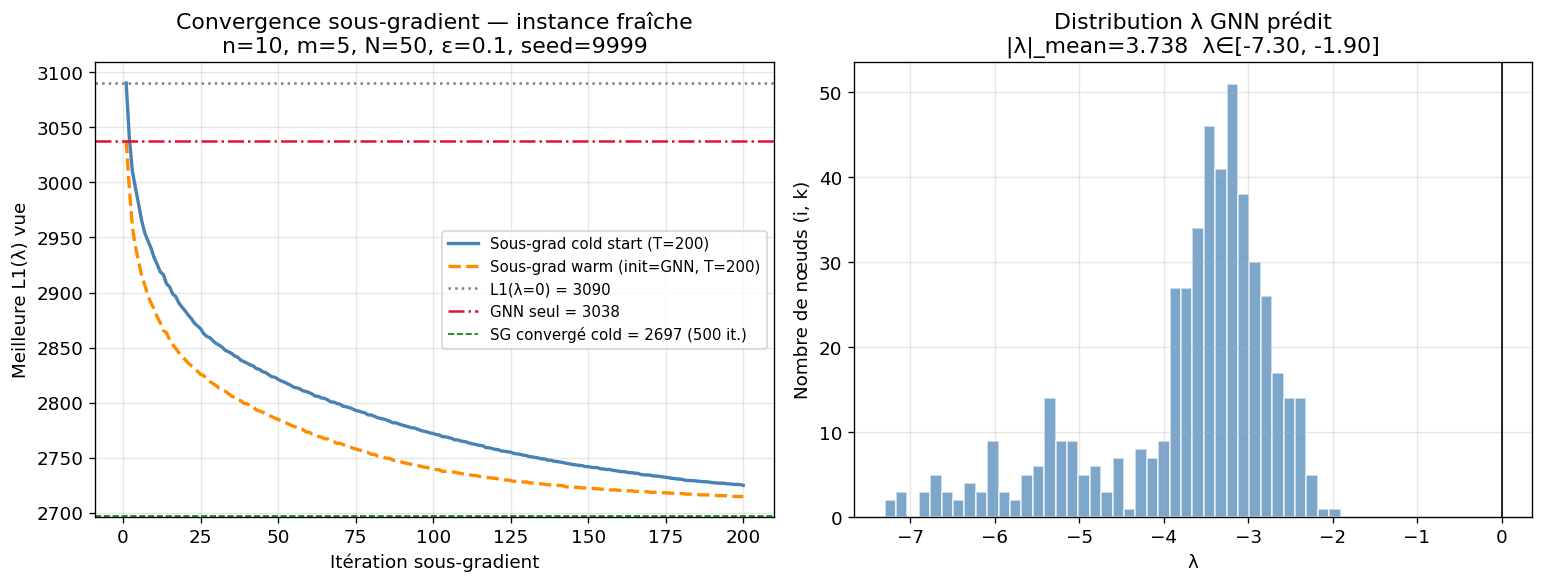

Figure sauvegardée : gnn/runs/fig_genmodel_inference.png


In [14]:
iters = np.arange(1, len(curve_cold) + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

# ── Gauche : convergence du sous-gradient ──────────────────────────────────
ax1.plot(iters, curve_cold, color="steelblue", lw=2,
         label=f"Sous-grad cold start (T={len(curve_cold)})")
ax1.plot(iters, curve_warm, color="darkorange", lw=2, ls="--",
         label=f"Sous-grad warm (init=GNN, T={len(curve_warm)})")

ax1.axhline(l1_init, color="gray",       lw=1.5, ls=":",  label=f"L1(λ=0) = {l1_init:.0f}")
ax1.axhline(l1_gnn,  color="crimson",    lw=1.5, ls="-.", label=f"GNN seul = {l1_gnn:.0f}")
ax1.axhline(l1_sg_cold, color="green",   lw=1,   ls="--",
            label=f"SG convergé cold = {l1_sg_cold:.0f} ({n_iters_cold} it.)")

ax1.set_xlabel("Itération sous-gradient")
ax1.set_ylabel("Meilleure L1(λ) vue")
ax1.set_title(
    f"Convergence sous-gradient — instance fraîche\n"
    f"n={n}, m={m}, N={N}, ε={epsilon}, seed={SEED}"
)
ax1.legend(fontsize=9)
ax1.grid(True, alpha=0.3)
ax1.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x:.0f}"))

# ── Droite : distribution des λ GNN ──────────────────────────────────────
lam_vals = lam_np.flatten()
ax2.hist(lam_vals, bins=40, color="steelblue", alpha=0.7, edgecolor="white")
ax2.axvline(0, color="black", lw=1)
ax2.set_xlabel("λ")
ax2.set_ylabel("Nombre de nœuds (i, k)")
ax2.set_title(
    f"Distribution λ GNN prédit\n"
    f"|λ|_mean={np.abs(lam_vals).mean():.3f}  "
    f"λ∈[{lam_vals.min():.2f}, {lam_vals.max():.2f}]"
)
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(REPO / "gnn" / "runs" / "fig_genmodel_inference.png", bbox_inches="tight")
plt.show()
print("Figure sauvegardée : gnn/runs/fig_genmodel_inference.png")